## Exploratory data analysis

target variable: search_occured 

### Observations

#### looking at the overall shape of the data, the rows and columns and the description.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [2]:
df = pd.read_csv("stop_search_cleaned_2018_2021.csv")
df.head()

/var/folders/8_/ppp0r4j15dn5lvst__77ql7c0000gn/T/ipykernel_43024/3984100468.py:1: DtypeWarning: Columns (18,32,41,42,43) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("stop_search_cleaned_2018_2021.csv")


,FieldInterviewID,NOPD_Item,EventDate,District,Zone,OfficerAssignment,StopDescription,ActionsTaken,VehicleYear,VehicleMake,...,exit_vehicle,pat_down,consent_form_completed,stripbody_cavity_search,legal_basises_relevant_factors,subject_restrained,subject_restraint_devices,event_dt,hour,night
0,"571,396",J0091121,2021 Oct 01 10:08:00 PM,5,D,5th District,OTHER,Stop Results: Physical Arrest;Search Occurred:...,NaN,NaN,...,NaN,No,No,No,NaN,Yes,Handcuffs,2021-10-01 22:08:00,22,1
1,"571,395",J0050921,2021 Oct 01 10:05:00 PM,4,E,4th District,TRAFFIC VIOLATION,Stop Results: Verbal Warning;Subject Type: Dri...,"2,009",HONDA,...,Yes,No,No,No,NaN,No,NaN,2021-10-01 22:05:00,22,1
2,"571,394",J0115921,2021 Oct 01 09:37:00 PM,7,F,7th District,TRAFFIC VIOLATION,Stop Results: Verbal Warning;Subject Type: Dri...,"2,009",LEXUS,...,Yes,Yes,No,No,Plain View,No,NaN,2021-10-01 21:37:00,21,1
3,"571,393",J0112821,2021 Oct 01 08:38:00 PM,3,J,ISB,TRAFFIC VIOLATION,Stop Results: Verbal Warning;Subject Type: Dri...,"2,011",FORD,...,No,No,No,No,NaN,No,NaN,2021-10-01 20:38:00,20,1
4,"571,391",J0110421,2021 Oct 01 08:27:00 PM,7,O,7th District,TRAFFIC VIOLATION,Stop Results: Verbal Warning;Subject Type: Dri...,"2,018",MERCEDES-BENZ,...,No,No,No,No,NaN,No,NaN,2021-10-01 20:27:00,20,1


In [3]:
df.describe()

,District,SubjectAge,Longitude,Latitude,hour,night
count,148205.000000,141915.000000,145891.000000,145891.000000,148205.000000,148205.000000
mean,4.438825,35.582863,-90.065136,29.965616,12.864134,0.534618
std,2.345925,13.716888,0.038394,0.031254,7.109137,0.498802
min,1.000000,0.000000,-90.189423,29.864307,0.000000,0.000000
25%,2.000000,25.000000,-90.091732,29.943506,8.000000,0.000000
50%,4.000000,33.000000,-90.070008,29.959071,14.000000,1.000000
75%,6.000000,44.000000,-90.043564,29.980243,19.000000,1.000000
max,8.000000,121.000000,-89.737833,30.361866,23.000000,1.000000


In [4]:
df.shape

(148205, 47)

## EDA

In [5]:
df = pd.read_csv("stop_search_train1.csv")

## Comparing the search rates for the reason for the stop

,records,search_rate
StopDescription,,
CALL FOR SERVICE,2376,29.88
CITIZEN CONTACT,225,14.67
CRIMINAL VIOLATION,757,54.03
FLAGGED DOWN,112,25.00
JUVENILE VIOLATION,29,17.24
OTHER,676,24.70
PRESENT AT CRIME SCENE,24,29.17
PUBLIC SAFETY RIDE,22,0.00
SUSPECT PERSON,1227,36.35


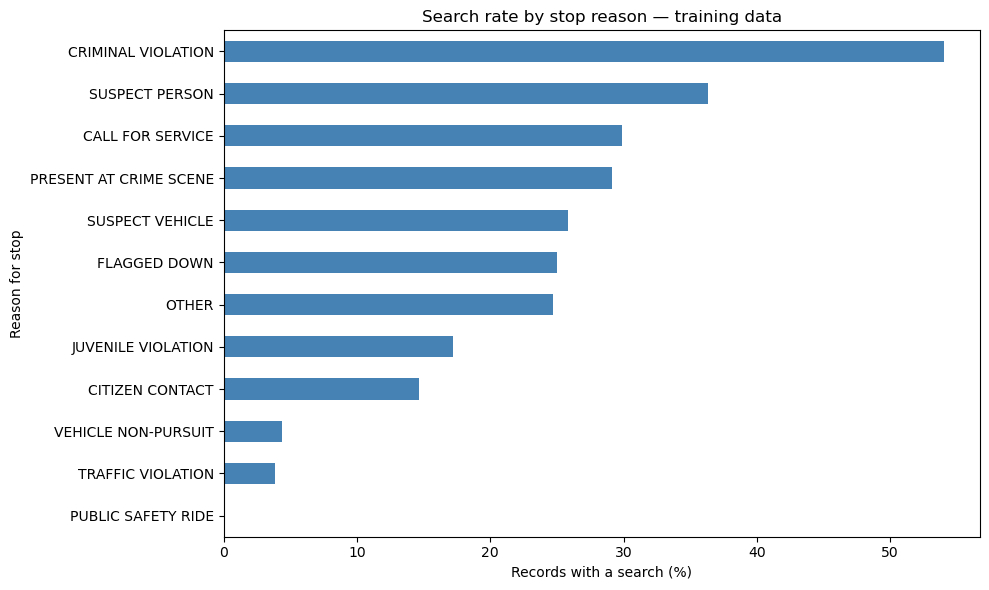

In [13]:
reason_sum = df.groupby("StopDescription")["search_occurred"].agg(
    records="size",
    search_rate="mean"
)
reason_sum["search_rate"] *= 100

display(reason_sum.round(2))

reason_sum["search_rate"].sort_values().plot(
    kind="barh", figsize=(10, 6), color="steelblue"
)

plt.xlabel("Records with a search (%)")
plt.ylabel("Reason for stop")
plt.title("Search rate by stop reason — training data")
plt.tight_layout()
plt.show()

The graph above shows that there is a significantly higher search stop reason for a criminal violation, almost more than double for many of the other call for service, present at crime scene and other violations. 

,records,searches,search_rate
District,,,
1,14096,784,5.56
2,16670,1056,6.33
3,26483,1030,3.89
4,11673,832,7.13
5,10603,742,7.00
6,16108,912,5.66
7,11661,708,6.07
8,14023,617,4.40


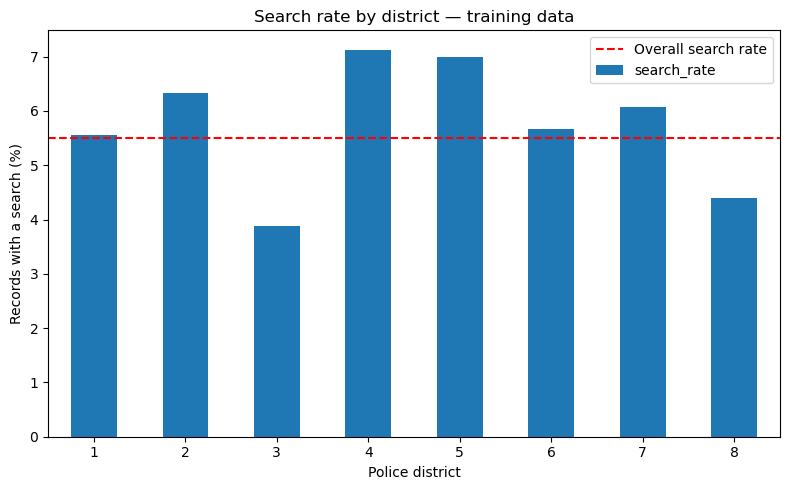

In [14]:

location_summary = df.groupby("District")["search_occurred"].agg(
    records="size",
    searches="sum",
    search_rate="mean"
)

location_summary["search_rate"] *= 100
display(location_summary.round(2))

location_summary["search_rate"].plot(
    kind="bar", figsize=(8, 5), rot=0
)

plt.axhline(
    df["search_occurred"].mean() * 100,
    color="red", linestyle="--", label="Overall search rate"
)
plt.xlabel("Police district")
plt.ylabel("Records with a search (%)")
plt.title("Search rate by district — training data")
plt.legend()
plt.tight_layout()
plt.show()

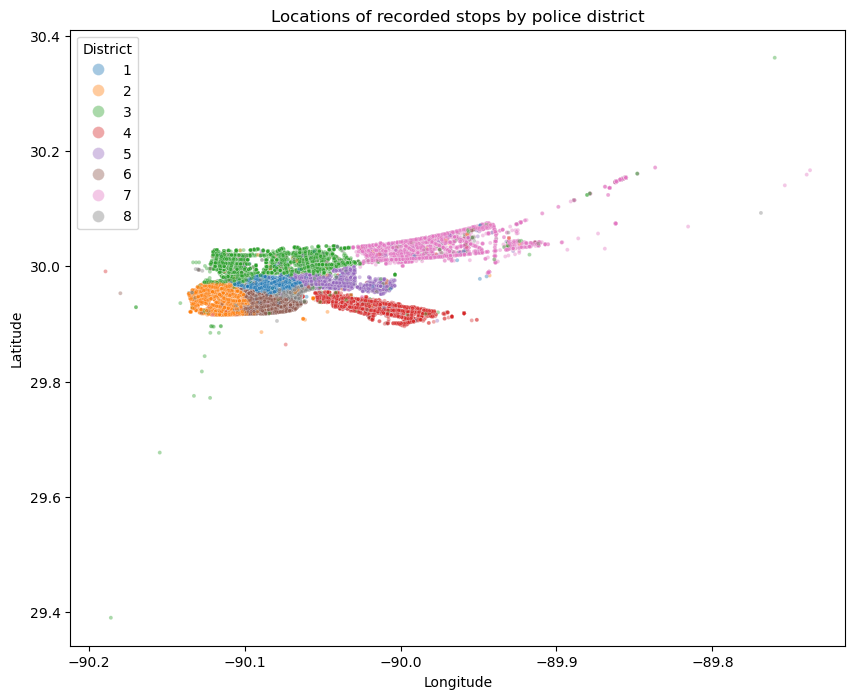

In [8]:

# Keep records with coordinates
locations = df.dropna(subset=["Latitude", "Longitude"]).copy()
locations["District"] = locations["District"].astype(str)

plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=locations,
    x="Longitude",
    y="Latitude",
    hue="District",
    hue_order=sorted(locations["District"].unique()),
    palette="tab10",
    s=8,
    alpha=0.4
)

plt.title("Locations of recorded stops by police district")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="District", markerscale=3)
plt.show()

,records,search_rate
night,,
0,61829,3.98
1,59488,7.09


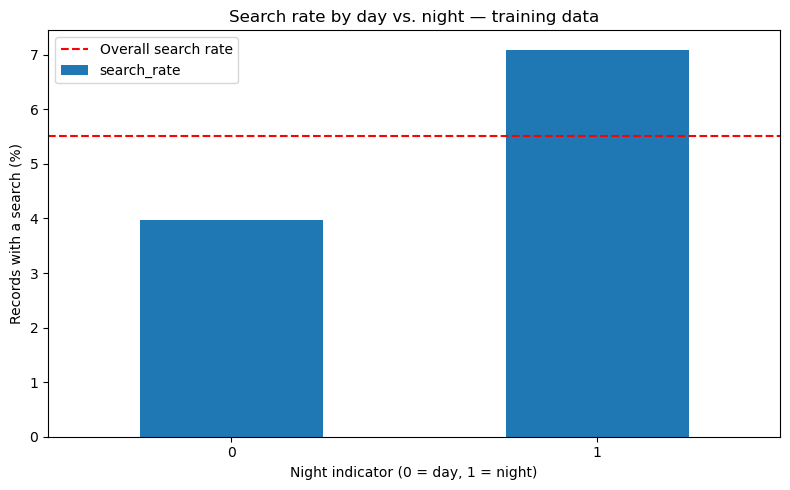

In [9]:
night_sum = df.groupby("night")["search_occurred"].agg(
    records="size",
    search_rate="mean"
)

night_sum["search_rate"] *= 100
display(night_sum.round(2))

night_sum["search_rate"].plot(
    kind="bar", figsize=(8, 5), rot=0
)

plt.axhline(
    df["search_occurred"].mean() * 100,
    color="red", linestyle="--", label="Overall search rate"
)

plt.xlabel("Night indicator (0 = day, 1 = night)")
plt.ylabel("Records with a search (%)")
plt.title("Search rate by day vs. night — training data")
plt.legend()
plt.tight_layout()
plt.show()

records  \
SubjectRace                               StopDescription               
AMER. IND.                                TRAFFIC VIOLATION       125   
ASIAN                                     CRIMINAL VIOLATION        3   
                                          TRAFFIC VIOLATION      1003   
BLACK                                     CRIMINAL VIOLATION      602   
                                          TRAFFIC VIOLATION     76787   
HISPANIC                                  CRIMINAL VIOLATION       15   
                                          TRAFFIC VIOLATION      2007   
NATIVE HAWAIIAN OR OTHER PACIFIC ISLANDER TRAFFIC VIOLATION       378   
UNKNOWN                                   CRIMINAL VIOLATION       12   
                                          TRAFFIC VIOLATION      3520   
WHITE                                     CRIMINAL VIOLATION      125   
                                          TRAFFIC VIOLATION     30067   

                                                              search_rate  
SubjectRace                               StopDescription                  
AMER. IND.                                TRAFFIC VIOLATION          2.40  
ASIAN                                     CRIMINAL VIOLATION        33.33  
                                          TRAFFIC VIOLATION          2.59  
BLACK                                     CRIMINAL VIOLATION        56.31  
                                          TRAFFIC VIOLATION          4.76  
HISPANIC                                  CRIMINAL VIOLATION        60.00  
                                          TRAFFIC VIOLATION          4.93  
NATIVE HAWAIIAN OR OTHER PACIFIC ISLANDER TRAFFIC VIOLATION          0.26  
UNKNOWN                                   CRIMINAL VIOLATION        16.67  
                                          TRAFFIC VIOLATION          1.22  
WHITE                                     CRIMINAL VIOLATION        46.40  
                                          TRAFFIC VIOLATION          1.91

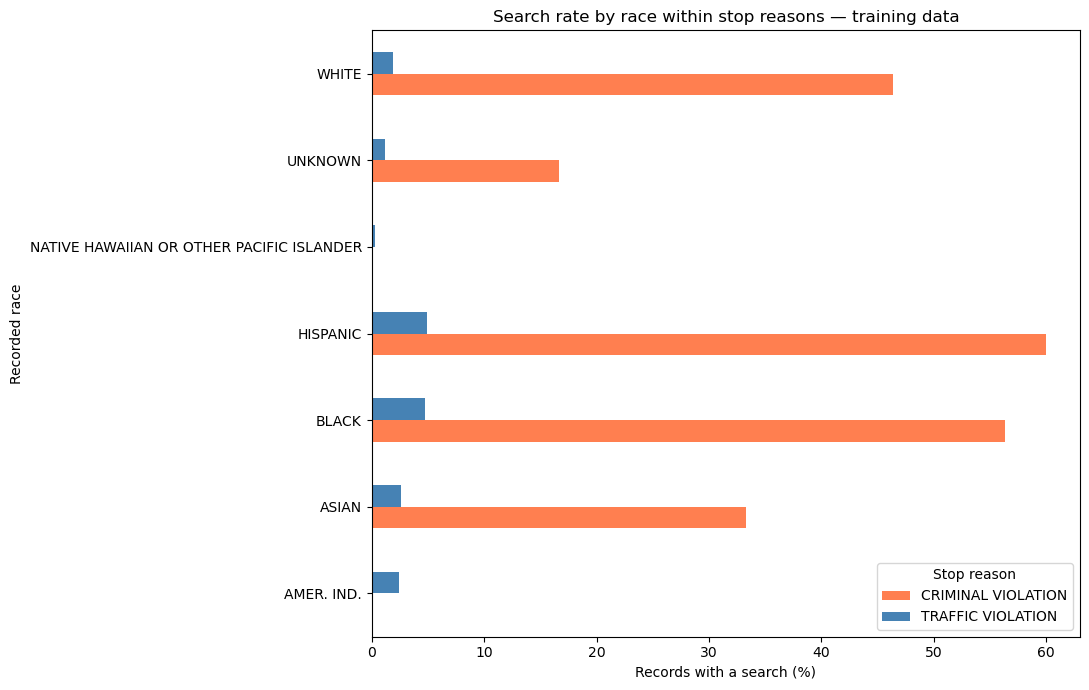

In [10]:
selected = df[df["StopDescription"].isin([
    "TRAFFIC VIOLATION", "CRIMINAL VIOLATION"
])]

race_sum = selected.groupby(
    ["SubjectRace", "StopDescription"]
)["search_occurred"].agg(
    records="size",
    search_rate="mean"
)
race_sum["search_rate"] *= 100

display(race_sum.round(2))

race_sum["search_rate"].unstack("StopDescription").plot(
    kind="barh", figsize=(11, 7), color=["coral", "steelblue"]
)

plt.xlabel("Records with a search (%)")
plt.ylabel("Recorded race")
plt.title("Search rate by race within stop reasons — training data")
plt.legend(title="Stop reason", loc="best")
plt.tight_layout()
plt.show()

,records,search_rate
age_group,,
Under 18,1751,13.02
18–24,20223,7.83
25–34,36450,6.83
35–44,24953,5.55
45–54,14313,4.17
55+,14704,2.51


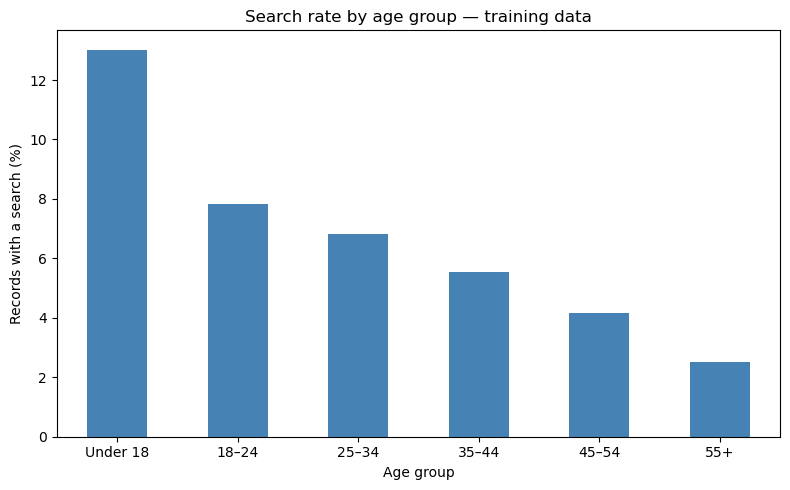

In [11]:
# Negative ages become missing; original column stays unchanged
df["age_clean"] = df["SubjectAge"].where(df["SubjectAge"] >= 0)

df["age_group"] = pd.cut(
    df["age_clean"],
    bins=[0, 18, 25, 35, 45, 55, float("inf")],
    labels=["Under 18", "18–24", "25–34", "35–44", "45–54", "55+"],
    right=False
)

age_sum = df.groupby("age_group", observed=True)["search_occurred"].agg(
    records="size",
    search_rate="mean"
)
age_sum["search_rate"] *= 100

display(age_sum.round(2))

age_sum["search_rate"].plot(
    kind="bar", figsize=(8, 5), rot=0, color="steelblue"
)

plt.xlabel("Age group")
plt.ylabel("Records with a search (%)")
plt.title("Search rate by age group — training data")
plt.tight_layout()
plt.show()